## 1. 시계열 데이터란?  

### 1-1 시계열 데이터의 정의  
> 시계열 데이터란? 시간의 흐름에 따라 일정한 간격, 순서대로 관측/기록된 데이터(주가, 기온, 매출...)  

#### 시계열 데이터의 조건   

- 시간 순서가 의미를 가짐 -> 순서 자체가 정보  

- 관측 간격이 일정 -> 매초 / 매시 / 매일 / 매년 처럼 주기가 일정해야 시점끼리 비교 가능  

횡단면 vs 시계열 데이터  

| 구분 | 횡단면 데이터 | 시계열 데이터 |
| --- | --- | --- |
| 관점 | **한 시점**에 **여러 대상**을 관찰 | **한 대상**을 **여러 시점**에 걸쳐 관찰 |
| 예시 | 2026년 서강대 학생 100명의 키 | 서강대 앞 식당 A의 2020~2026년 월별 매출 |
| 행 순서를 섞으면? | 아무 문제 없음 | **의미가 사라짐** |  


#### 단변량 시게열, 다변량 시계열  

**단변량 시계열**  
- 시간에 따라 하나의 변수 관측  
- 자기 자신의 과거값만으로 미래 예측  

**다변량 시계열**  
- 시간에 따라 여러변수 동시 관측  
- 자신뿐 아니라 다른 변수들의 영향까지 함께 고려  


#### 시계열 분석과 목적  

> 시계열 분석? 시간순서대로 쌓인 데이터에서 패턴을 찾아내고, 이를 바탕으로 미래값을 예측하는 분석방법

**시계열 분석의 주 목표** : 지금까지의 기록을 보고 다음 시점의 값을 추정하는것
시계열 이해 -> 전처리 -> 정상성 판단 -> 모델링&예측  


### 1-2 시계열 데이터의 특성   

#### 시간의존성   
> 시간의존성? 데이터가 시간에 따라 변하고, 현재 시점의 값이 과거 시점의 값에 영향을 받는 성질  

- 특징  
    - 과거의 값이 현재의 값에 영향을 미침  
    - 보통 가꺼운 과거일수록 영향 큼  
    - 순서를 섞으면 X  
=> 시간에 따른 변화는 일정하게 반복괴는 모양(계절성), 전반적으로 감소 OR 증가하는 모양(추세)로 나뉨  

#### 계절성 & 추세  

> 계절성? 일정한 주기로 비슷한 패턴이 반복되는 성질  

> 추세? 시간의 흐름에 따라 데이터가 장기적으로 증가 OR 감소 하는 현상   

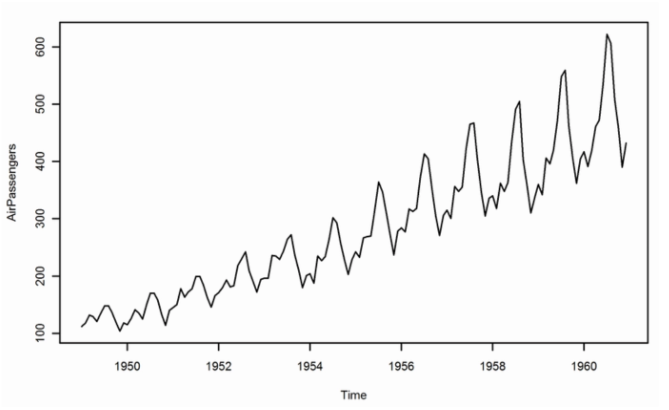  

#### 자기상관성(Autocorrelation)  

> 자기상관성? '자기 자신'끼리 '상관관계'를 갖는 특성  

- 한 시계열 안에서, 현재 값과 과거 값이 얼마나 비슷하게 움직이는지를 나타내는 정도  
- 시간이 지남에 따라 값들 간에 일정한 패턴이나 반복 존재  
- 시차를 바꿔가며 계산하면 반복주기(게절성)를 찾을 수 있음  

=> 자기상관성이란, 과거 값으로 지금 값을 짐작할 수 있는 정도  

But, 자기상관성이 있다는것은 회귀분석이 불가능하다는것을 의미!  

### 1-3 시계열 데이터의 분석요인   

1. 추세요인(Trend Factor) : 시계열이 시간 전반에 걸쳐 증가하거나 감소하는 경향성을 나타내는 요인  

2. 계절요인(Seasonal Factor) : 1년 이내의 일정한 주기로 같은 패턴이 반복되는 요인  

3. 순환요인(Cycle Factor) : 계절성보다 더 길고 불규칙한 주기로 반복되는 변동  

4. 불규칙 요인(Irregular Factor) : 시계열에서 추세, 계절, 순환요인을 모두 제거하고 남은 나머지 움직임  

**4가지 분석요인 정리**  

| 요인 | 의미 | 주기 | 예측 가능성 | 예시 |
| --- | --- | --- | --- | --- |
| 추세 (T) | 장기적인 방향 | 없음 | 높음 | 1인 가구 수 증가 |
| 계절 (S) | 정해진 주기의 반복 | 고정 (1년 이내) | 높음 | 여름 에어컨 판매 급증 |
| 순환 (C) | 불규칙한 주기의 오르내림 | 불규칙 (수년) | 낮음 | 경기 호황, 불황 |
| 불규칙 (I) | 설명되지 않는 나머지 | 없음 | 불가능 | 폭우로 매출 급감 |    


## 2. 시계열 데이터 전처리  

> 전처리 프로세스 : 데이터 확인 -> 결측치 탐지 & 처리 -> 이상치 탐지 & 처리 -> 평활화 -> 요소 분해 -> 정상성 판단 & 확보    


### 2-1 결측치/이상치 처리   

### 결측치  
일반 데이터에선 결측치 행을 지워도 문제가 없었더라도 시계열에선 그렇지 않음  
-> 행을 지우면 관측 간격이 깨져 시점끼리 비교 불가, 전체 평균으로 지우면 시간 흐름 무시하는 문제 발생  

**결측치 처리방법 정리**  

| 방법 | 설명 | 시계열에서의 한계 |
| --- | --- | --- |
| 삭제 | 결측치가 있는 시점을 제거 | 관측 간격이 깨짐 → 결측이 매우 적고, 데이터 맨 앞이나 맨 뒤일 때만 고려 |
| 단순 대치 | 평균, 중앙값, 최빈값으로 채움 | 추세와 계절성을 무시함 |
| 보간 | 앞뒤 관측값을 이용해 사이의 값을 추정 | 앞뒤 값이 있어야 함 -> 시계열에서 가장 많이 사용 |
| 이동평균 대치 | 결측 시점 주변 일정 구간의 평균으로 채움 | 구간 크기를 정해야 함 |
| 머신러닝 기법 | KNN, 회귀 모델 등으로 결측값을 예측해서 채움 | 정교하지만 복잡하고 계산량이 많음 |   

-> 시계열에서 가장 중요하고 많이 쓰이는 방법 : 보간법  

#### 보간법  

> 보간법 : 주어진 데이터 포인트 값을 이용해, 두 관측값 사이의 비어있는 값을 추정하는 방법  

**보간법의 과정**  
1. 결측 위치 확인  
2. 앞, 뒤 관측값 확인  
3. 두 점을 연결하는 규칙 정하기 : 곡선, 직선 기타 등등... -> main part(보간법의 종류)  
    - 선형보간, 스플라인보간, 다항식 보간, 조각별 상수 보간
4. 값 추정  

#### 이상치  
> 이상치 : 데이터의 일반적인 패턴에서 크게 벗어난 극단적인 값  
시점이 중요, 같은 값이더라도 시점에 따라 정상일수도 이상일수도 있음  
-> 값의 크기만 보는것이 아니라 추세와 계절성까지 고려해서 판단  

**이상치 탐지 방법**  
1. IQR Rule-base Anomaly Detection : 세션에서 배운 내용  
    - 주기성이 없거나 비교적 안정적인 구간에서 이상치 탐지시 시용  
    - 계산이 간단하고 직관적, 데이터가 정규 분포를 따르지 않아도 사용 가능  
    - 추세나 계절성 강하면 사용 불가, 분포가 비정상적일 경우 오탐률 높음  

2. Z-score : 일반적인 표준정규분포 환산식에서 구하는 z-score(보통 3 이상이면 이상치로 판단)  
    - 계절성/추세가 약하거나 값의 변동폭이 일정한 시계열에서 효과적  
    - 이동 평균과 이동 표준편차로 구간마다 Z-score를 계산시 추세의 영향을 줄일 수 있음 (Rolling Z-score)  
    - 계산이 간단하고 해석이 쉬움  
    - 데이터가 정규분포를 따른다고 가정, 평균과 표준편차가 이상치 자체에 영향을 받아서 큰 이상치가 기준을 끌어올려 오히려 잘 안잡힐 수 있음  

3. STL분해 : 시계열을 추세(T), 계절(S), 잔차(R)로 분해하는 방법  
    $Y_t = T_t + S_t + R_t$  
    - 잔차가 특정 임계값 초과시 이상치 탐지, 계절성이나 추세가 뚜렷한 시계열에 적합  
    - 추세와 계절성을 제거하고 진짜 이상한 값만 잡아낼수 있음, 비정상 시계열에도 유연하게 적용 가능  
    - 매우 긴 시계열에선 파라미터 튜닝 필요, 계산 비용큼  


**이상치 탐지 모델**  
1. 분류 및 회귀 트리(CART) : 데이터를 조건에 따라 계속 나눠가며 예측하는 의사결정 나무 모델  
    - 과거 구간의 값을 입력하여 다음시점의 값을 예측하고 예측오차 기반으로 이상치 판단  

2. 클러스터링 기반 이상 탐지 : 비슷한 데이터끼리 묶는 군집화를 한 뒤, 어느 군집에도 잘 속하지 않는 데이터를 이상치로 판단  
    - 시계열의 특징 추출후, 각 시점을 벡터로 표현해 클러스터링 수행, 중심으로부터 거리나 군집 밀도를 기준으로 하여 이상치 판단  

3. 오토 인코더 : 입력 데이터를 작게 압축했다가 다시 원래대로 복원하도록 학습하는 신경망 -> 이상치가 들어오면 제대로 복원하지 못하여 오차가 기준보다 커지면 이상치로 판단  
    - 시계열을 일정 길이로 잘라 정상구간을 학습 시키고, 테스트 구간의 복원오차가 큰곳을 이상으로 탐지  


Q. 이상치를 찾았다면 처리 방법은?  
A. 오류인지 실제 사건인지 확인한뒤 처리 방법 선정, (삭제, 단순 대치, 보간)  


### 2-2 평활화   
> 평활화 : 시계열 데이터의 자잘한 오르내림(노이즈)을 줄여 데이터를 부드럽게 만드는 기술  

> 이동평균 ; 일정한 개수의 연속된 데이터를 묶어 평균내고, 그 묶음을 한칸씩 옮겨가며 평균을 계속 계산  
$ MA_t = \frac{Y_t + Y_{t-1} + \cdots + Y_{t-N+1}}{N} $

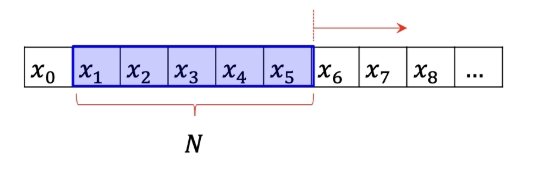  

- N이 작으면?  
    - 원래 데이터와 비슷하게 움직임. 최근 변화에 빠르게 반응하나 노이즈가 많이 남음  
- N이 크면?  
    - 그래프가 매끄러워짐. 큰 흐름이 잘보이나 변화에 늦게 적응하고, 세부 변화가 사라짐  

**이동평균 사용 목적**  
1. 노이즈 제거 & 추세 파악  
2. 계절성 제거  
3. 결측치, 이상치 대치  
4. 예측의 기초 자료  

**이동평균의 유형**  
묶음안의 값들에 어떻게 가중치를 주느냐에 따라 분류  
1. 단순 이동 평균(Simple Moning Average) : 묶음 안의 모든 값에 똑같은 가중치  
2. 가중 이동 평균(Weighted Moving Average) : 최근 값일수록 더 큰 가중치  
3. 지수 이동 평균(Exponential Moving Average) : 최근 값일수록 큰 가중치를 주되, 과거로 갈수록 가중치가 지수적으로 줄어듬  

### 2-3 요소분해   
> 요소분해? 섞여있는 시계열을 추세(T), 계절(S), 순환(C), 불규칙(R)요인으로 다시 나누는 과정  

Q. 요소분해를 하는 이유? 
A. 각각의 패턴을 명확히 이해 가능, 변동 원인 분석 가능, 더 정교한 분석 가능  

#### 분해 모형   
1. 가법 모형(Additive Model) $Y_t = T_t + S_T + R_t$   
- 시계열 = 추세, 계절, 잔차의 합, 시계열의 관측값은 변동 요인들의 가법으로 설명될 수 있다고 가정  
- 각 변동 요인들이 독립적으로 더해지며, 모든 요소의 영향이 일정  
- 시계열 전체에서 계절성의 진폭이 일정할 때 적합  

2. 승법 모형(Multiplicative Model) $Y_t = T_t x S_T x R_t$  
- 시계열 = 추세, 계절, 잔차의 곱, 시계열의 관측값은 변동요인들의 승법으로 설명될 수 있다 가정  
- 추세가 커질수록 계절성이나 불규칙성의 효과도 비례해서 증가  
- 진폭이 시간이 지남에 따라 달라질때 적합  

**가법모형 vs 승법모형**  

| 구분 | 가법 모형 | 승법 모형 |
| --- | --- | --- |
| 결합 방식 | 더하기 | 곱하기 |
| 계절 변동 크기 | 추세와 상관없이 일정 | 추세에 비례해서 커짐 |
| 계절 요인 단위 | 원래 데이터와 같은 단위 (잔, 원) | 비율 (배, %) |
| 그래프 모양 | 물결 높이가 일정 | 물결 높이가 점점 커짐 |  

#### 분해 방법(구현 알고리즘)    
1. Seosonal Decompose - MA기반 분해 
이동평균으로 추세를 먼저 뽑아낸 뒤, 나머지에서 계절과 잔차를 차례로 분리   
- 작동 방식  
    1. 추세 추출 : 중심 이동 평균을 적용하여 추세 성분 추정  
    2. Detrending(추세 제거) : 원래 데이터에서 추세 제거(계절+잔차 만 남김)  
    3. 계절성 추정 : 추세 제거 데이터에서 계절 요인 도출  
    4. 잔차 산출 ; 원래 데이터에서 추세와 계절 모두 제거 후 남은 값  

2. STL - LOESS 기반 분해 (Seasonal decomposition한계 보완, 이동평균 대신 LOESS사용)  
각 지점마다 주변 데이터만 사용해서 작은 회귀선을 그리고 이를 이어붙여 부드러운 곡선을 만드는 방법  
- 작동 방식 : Inner Loop, Outer Loop 이중 반복 구조   
    - Inner Loop : 추세와 계절 번갈아 추정  
        1. 원래 데이터에서 현재 추세를 빼서 추세를 제거  
        2. 추세를 제거한 데이터를 같은 계절 위치끼리 모아 LOESS로 부드럽게 만듦 -> 계절 요인(S) 추정  
        3. 원래 데이터에서 계절 요인을 빼서 계절성을 제거  
        4. 계절성을 제거한 데이터에 LOESS를 적용 → 추세 요인(T) 추정  
        5. 새로 구한 추세로 다시 1번부터 반복하며 T와 S를 점점 정확하게 다듬음  
    - Outer Loop : 이상치 영향 줄이기  
        1. Inner Loop가 끝나면 잔차(R = Y − T − S)를 계산  
        2. 잔차가 유독 큰 시점(이상치일 가능성이 높은 시점)에 작은 가중치를 부여  
        3. 이 가중치를 반영해서 Inner Loop를 다시 수행  



## 3. 정상성 판단   

### 3-1 정상성의 정의 / 3-2 강한 정상성과 약한 정상성   
> 정상성이란(Stationarity)? 시계열의 통계적 특성이 시간에 따라 변하지 않는 성질  
데이터가 시간에 상관없이 일정한 성질을 띄는 것  

> 강한 정상성? 시계열의 확률분포 자체가 시간에 따라 전혀 변하지 않는 성질 -> 어떤 시점을 보더라도 분포가 완전히 같음  
평균, 분산 뿐만아니라 왜도, 첨도등 분포의 모든 특성이 일정,그러나 현실데이터에선 이런 상태를 거의 찾기 어려움  

> 약한 정상성? 분포 자체가 아니라 평균, 분산, 자기공분산만 시간에 따라 일정. 아떄, 평균과 분산은 시점에 관계없이 일정, 자기 공분산은 시차에만 의존  
현실 데이터에도 적용 가능, 대부분의 시계열 모델이 가정  

### 3-3 정상성의 판단 - 시각 / 통계   

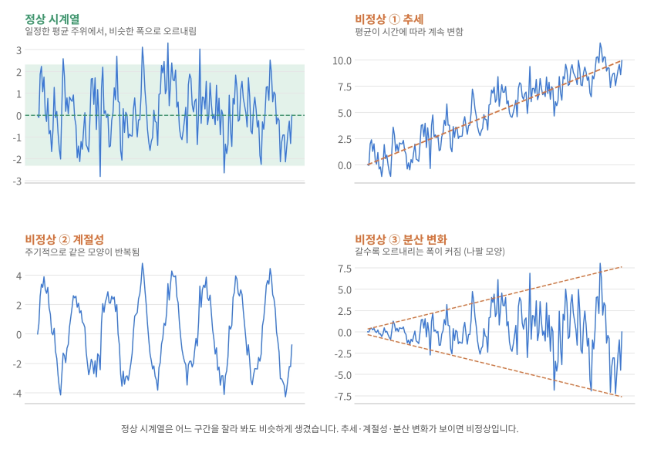  

**정상 시계열의 대표적인 그래프 특징**  
- 일정한 수평선(평균)을 중심으로 위아래로 오르내림  
- 오르내리는 폭이 시간에 상관없이 비슷함  
- 평균에서 벗어나도 다시 평균으로 돌아오는 경향 (평균 회귀)  
- 특정 주기로 반복되는 패턴이 없음  

**비정상 시계열의 대표적인 그래프 특징**  
- 추세 : 그래프가 계속 오르거나 내림 ->  평균이 변함  
- 계절성 : 일정한 주기로 같은 모양이 반복됨 -> 시점에 따라 평균이 달라짐  
- 분산 변화 : 시간이 지날수록 오르내리는 폭이 커지거나 작아짐 (나팔 모양) -> 분산이 변함  

그래프는 직관적이지만 주관적, 통계적 검정을 통해 객관적으로 파악해야함!  

> 단위근? 시계열을 포함하는 식의 근이 1이되는 경우   

$Y_t = \phi Y_{t-1} + \varepsilon_t$ 에서  
- $\phi = 0.5$(정상) : 매일 절반씩만 충격이 남으므로 점점 작아지다 사라짐, 값이 튀어도 결국 평균으로 돌아옴  
- $\phi = 1.0$(비정상) : 어제 값이 100% 그대로 남아서 한번 생긴 충격이 사라지지 않고, 매일 새 충격이 누적  
-> 평균으로 돌아오지 않고, 분산이 계속 증가 => 평균과 분산이 시간에 따라 변하므로 약한 정상성 조건 성립 불가  

**단위근 검정법**  
1. ADF(Augmented Dickey-Fuller)검정 : 시계열이 과거 값에 얼마나 의존하는지 측정   
- 과거 값의 영향이 시간이 지남에 따라 점점 사라지면 정상 시계열, 누적되어 사라지지 않으면 단위근이 존재하는 비정상 시계열로 판단
2. KPSS(Kwiatkowski-Phillips-Schmidf-Shin)검정 : 시계열이 일정한 평균 수준을 유지하는지를 측정  
- 평균이 시간에 따라 흔들리지 않으면 정상, 평균 자체가 계속 변하고 있으면 비정상으로 판단  

| ADF 결과 | KPSS 결과 | 진단 | 다음 액션 |
| --- | --- | --- | --- |
| 정상 | 정상 | 정상 시계열 | 바로 모델링 진행 |
| 비정상 | 비정상 | 비정상 시계열 | 차분 등으로 정상성 확보 후 재검정 (3-4) |
| 비정상 | 정상 | 추세 정상 시계열 | 추세 제거 후 재검정 |
| 정상 | 비정상 | 차분 정상 시계열 | 차분 후 재검정 |


### 3-4 정상성 확보 방법   
1. 추세 제거 : 시계열이 장기적으로 한 방향으로 계속 오르거나 내려서 시간에 따라 평균이 변하는 경우 적용  
> 차분(Delta) : $\Delta Y_t = Y_t - Y_{t-1}$
차분을 통해 추세와 단위근이 사라짐으로서 정상성 확보 가능  
차분은 1차차분, 2차차분, 역차분 등이 있음  

2. 게절성 제거 : 시계열이 일정한 주기마다 같은 모양을 반복해서, 시점에 따라 평균이 달라지는 경우 적용  
> 계절 차분 : $\Delta_m Y_t = Y_t - Y_{t-m}$ 오늘 값에서 한 주기 전의 값을 빼는 방법  

3. 분산 안정화 : 시계열의 오르내리는 폭이 시간이 지날수록 커지거나 작아져서 분산이 일정하지 않은 경우에 적용  
로그 변환을 통해 값이 커질수록 커지던 변동폭을 비슷한 크기로 정리 가능



## 4. 단변량 시계열 뷴석   

### 4-1 안정적 시계열 분석   

#### 자기 회귀 모델(Autoregressive Model, AR)  
> AR? 오늘 값을 자기 자신의 과거 값으로 설명하는 모형  

- AR(p)모형 : 과거 p개 시점의 값 사용  
$ y_{t}=c +\phi_1y_{t-1}+\phi_2y_{t-2}+...+\phi_py_{t-p}+\varepsilon _t $  
시차마다 계수 존재, 값은 데이터에서 추정  

- AR(1)모형 : 바로 전 시점의 값 하나만 사용, *i.e.AR(p)모형에서 p=1인 경우*  

#### 이동 평균 모델(Moving Average, MA)  
> MA? 오늘 값을 과거의 충격으로 설명하는 모델  

- MA(q) 모형 : 과거 q개 시점의 충격 사용   
$ y_t = \mu +\varepsilon_t+ \theta_1\varepsilon_{t-1}+\theta_2\varepsilon_{t-2}+...+\theta_q\varepsilon_{t-q} $   
    - MA(2)에서 계수가 0.6과 0.3이면, 충격 100의 여파는 다음 날 60, 이틀 뒤 30, 사흘 뒤 0. 계수가 여파의 크기로 그대로 나타나고, q일 뒤까지 남았다가 그다음 날부터 0이 됨  

- MA(1) 모형 : 바로 전 시점의 충격 하나만 적용 *i.e. MA(q)모형에서 q=1인 경우*  

**AR vs MA**  

|  | AR | MA |
| --- | --- | --- |
| 한 줄 요약 | 손님이 어제 손님 수를 보고 온다 | 손님이 어제 방송을 보고 온다 |
| 오늘 충격 | 오늘 값에 그대로 들어감 | 오늘 값에 그대로 들어감 |
| 지나간 충격 | 어제 값이라는 그릇에 담겨 넘어옴 | 충격 자체가 직접 넘어옴 |
| 영향이 가는 기간 | 끝없이 이어지며 옅어짐 | 정해진 날수 뒤에 끊김 |  

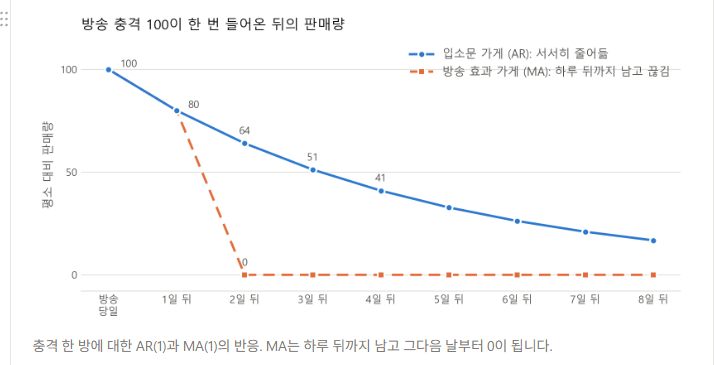  



#### AR, MA의 제약조건  

AR, MA를 쓰려면 정상성과 가역성이 필요  

|  | 정상성 | 가역성 |
| --- | --- | --- |
| 뜻 | 충격을 받아도 평소로 돌아온다 | 판매량 기록으로 지난 충격을 계산해 낼 수 있다 |
| AR 모형 | 계수 조건이 필요 | 항상 만족 |
| MA 모형 | 항상 만족 | 계수 조건이 필요 |
| 계수 조건 | AR(1)이면 계수의 절댓값이 1보다 작다 | MA(1)이면 계수의 절댓값이 1보다 작다 |  

1. 정상성 : 3절에서 다룸  

- AR모델의 정상성 조건 :   
    - AR(1)은 계수의 절댓값이 1보다 작으면 OK  
    - AR(p)의 경우, 특성방정식 $ 1-\phi_1 z-\phi_2 z^2-\dots-\phi_p z^p=0 $ 의 모든 근의 절댓값이 1보다 커야 함  

- MA 모델의 정상성 : 항성 성립


2. 가역성 : 지난 충격을 거꾸로 계산해 낼 수 없는 성질  

- AR모델의 가역성 조건 : 항상 가역  

- MA 모델의 가역성 :   
    - MA(1)은 계수의 절댓값이 1보다 작으면 OK  
    - MA(q)의 경우, 특성방정식 $ 1+\theta_1 z+\theta_2 z^2+\dots+\theta_q z^q=0$ 의 모든 근의 절댓값이 1보다 커야 함    


#### ARMA   
> ARMA = AR + MA : 오늘 값이 과거 값과 과거 충격 양쪽의 영향을 받음  
$ y_t = c+\phi_1y_{t-1}+\dots+\phi_py_{t-p}+\varepsilon_t+\theta_1\varepsilon_{t-1}+\dots+\theta_q\varepsilon_{t-q} $  

- Example : AR(1) 계수 0.5, MA(1) 계수 0.4인 가게에 방송 충격 100이 들어왔다고 가정  

|  | 당일 | 다음 날 | 이틀 뒤 | 사흘 뒤 |
| --- | --- | --- | --- | --- |
| 입소문만 있는 가게 (AR) | 100 | 50 | 25 | 12.5 |
| 방송 효과만 있는 가게 (MA) | 100 | 40 | 0 | 0 |
| 둘 다 있는 가게 (ARMA) | 100 | 90 | 45 | 22.5 |  

ARMA모형도 마찬가지로 AR부분이 정상성을, MA부분이 가역성 조건을 각각 만족해야함  

#### 차수 결정 방법 : 자기상관 함수(ACF, PACF)   
> 자기 상관 계수(Auto Correlation Function, ACF) : 오늘 값과 k시점 전 값이 얼마나 닮았는지를 상관계수로 잰 값  $ \rho(k)=\frac{Cov(y_t,\ y_{t-k})}{Var(y_t)} $  

- -1 ~ 1 사이의 값을 가지며(시차 0에선 1) 중간 날짜를 거쳐 온 영향까지 합쳐서 잼. 그래프 점선 안쪽이면 0으로 봄(점선은 보통 $|1.96/\sqrt{n}|$)  

> 부분 자기 상관 계수(Partial Autocorrelation Function, PACF) : 중간 시점들의 영향을 빼고, 오늘 값과 k시점 전 값이 직접 얼마나 닮았는지 잰 값 $ \phi_{kk} = Corr(y_t,\ y_{t-k}\mid y_{t-1},\dots,y_{t-k+1}) $


### 4-2 불안정 시계열 분석   

불안정 시계열은 돌아갈 평소가 없는, 즉 정상성이 없는 시계열 *i.e. 추세나 계절성이 존재 -> 각각마다 처방이 다름*  

| 평소가 없는 이유 | 모습 | 처방 | 다루는 곳 |
| --- | --- | --- | --- |
| 추세 | 계속 오르거나 내림. (새로 생긴 가게,아이 키) | 차분 (d) | ARIMA |
| 계절성 | 달마다 평소가 다름. (붕어빵) | 계절 차분 (D) | SARIMA |  

#### ARIMA(Autoregressive Integrated Moving Average)   
> ARIMA = ARMA + 차분  
- $ARIMA(p,d,q)$  
    - p ; AR차수, d : 차분 횟수, q : MA차수  

**ARIMA의 흐름**  
1. 차분을 진행해 증감 생성  
2. 증감을 ARMA로 예측  
3. 예측한 증감을 더해 판매량으로 되돌림

#### SARIMA(Seasonal ARIMA)  
> SARIMA = ARIMA + 계절 차분 + 계절 AR + 계절 MA  
$SARIMA = (p,d,q) + (P,D,Q)_m$  

**SARIMA의 흐름**  
1. 게절 차분을 진행  
2. AR과 MA를 사용하여 증감 예측(지난달 항과 작년 같은 달 항 input)  
3. 판매량으로 되돌림  

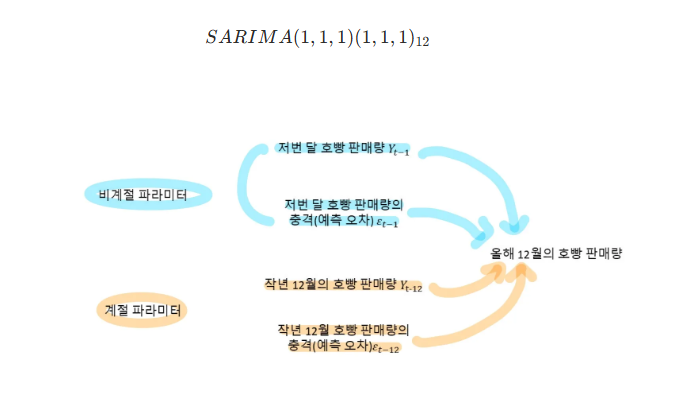  


## 5. 다변량 시계열 분석  

### VAR(Vector Autoregression)  

> VAR은 AR을 변수 여러개로 넓힌것  

- 단변량 AR(1)은 식이 하나, 자가 지신의 어제 값만 들어감  
$ X_t = a_1 X_{t-1} + \varepsilon_t $  

- 다변량 VAR(1)은 변수마다 식이 하나씩 있고, 각 식에 모든 변수의 전 시점 값이 들어감  
$ X_t = a_{11} X_{t-1} + a_{12} Y_{t-1} + \varepsilon_{x,t} $  
$ Y_t = a_{21} X_{t-1} + a_{22} Y_{t-1} + \varepsilon_{y,t} $  

- $a_11$과 $a_22$는 자기 자신에게서 넘어오는 영향  
- $a_12$와 $a_21$은 서로에게 주는 영향  

#### VAR은 어떤 경우에 추천?  
**VAR모형이 적합한 경우**  
- 변수들이 서로 영향을 주고받는 경우  
- 예측뿐 아니라 "한 변수가 변하면 다른 변수가 며칠에 걸쳐 어떻게 반응하는가"를 알고 싶을 때  
- 모든 변수가 정상이거나, 차분하면 정상이 되는 경우  
- 변수의 수가 적고 데이터가 충분한 경우  

**VAR모형이 부적합한 경우**  
- 영향이 한 방향뿐인 경우  
- 변수는 많은데 데이터가 적은 경우  
- 비율이 고정되지 않은 관계가 강한 경우-> 이떄는 6장의 딥러닝을 고려  


#### VAR모델을 이용한 분석 방법  

> 충격 반응 함수(Impulse-Response Function, IRF) : 한 변수에 충격을 한 번 주었을 때, 다른 변수가 시간에 따라 어떻게 반응하는지를 보는 도구  

> 예측오차 분산 분해(Variance Decomposition) : 예측이 빗나가는것은 예측한 뒤에 들어올 충격을 모르기 때문, 분산 분해는 빗나간 정도를 어느쪽 충격 탓인가로 나누어 비율을 보여줌  

-> 충격 반응 함수가 '어떻게 반응하는가'를 분산 분해가 '누구의 영향이 얼마나 큰가'를 보여줌  


## 6. 딥러닝을 활용한 시계열 분석  

데이터가 많으면 처리속도가 느려지고, 크기가 고정된 데이터만 가능하고, 비선형 패턴 포착이 어렵다는 전통 통계 모델의 한계 완화를 위해 딥러닝이 등장하게 됨!  

#### 순환 신경망(RNN계열)  
RNN / LSTM / GRU (Review)  
RNN : 이전 시점의 정보를 현재로 전달하는 순환 구조의 기본 신경망
LSTM : 게이트 메커니즘으로 장기 기억을 유지할 수 있도록 개선한 RNN
GRU: LSTM을 단순화하여 더 빠르게 학습하면서도 비슷한 성능을 내는 모델  

- 적합한 경우?  
    - 순차적 패턴이 중요한 시계열 데이터  
    - 과거 정보가 미래 예측에 영향을 주는 문제  
    - 시계열 길이와 목적에 따라 모델 선택 가능  
    *e.g. 주가, 센서, 재무 데이터, 사용자 행동 로그*  

- 부적합한 경우?  
    - 매우 긴 시계열(수천~수만 step)에서는 학습이 어려울 수 있음  
    - 병렬 처리 효율이 낮음  
    - Transformer 계열 대비 학습 속도가 느린 편  

| 모델 | 장점 | 단점 | 사용 예시 |
| --- | --- | --- | --- |
| RNN | 간단, 빠름 | 장기 의존성 학습 불가 | 짧은 시계열 (일주일 주가) |
| LSTM | 장기 의존성 학습 가능 | 복잡, 느림 | 분기별 재무제표 예측 |
| GRU | LSTM보다 빠름, 적당한 성능 | LSTM보다 장기 의존성 약함 | 실시간 센서 데이터 예측 |  

#### Transformer 계열  
1. Informer(장기 예측 특화)  
- 특징 : 불필요한 연산을 줄여 계산 복잡도를 대폭 낮춤  
- 실무 강점 : 매우 긴 시계열 데이터 처리에 강력  

2. Autoformer(주기성 포착 특화)  
- 특징 : 시계열의 전통적 기법인 '요소 분해(추세/계절성)' 개념을 딥러닝 구조에 직접 결합한 모델  
- 실무 강점 : 연간 계절성 등 주기 패턴이 뚜렷하게 나타나는 판매량 예측에 압도적인 성능을 보임  

3. TFT (Temporal Fusion Transformer - 실무 활용도 1위)  
- 특징 : 과거 데이터뿐만 아니라 다양한 외부 변수(날씨, 휴일 유무 등)를 섞어서 예측할 수 있는 다목적 아키텍처  
- 실무 강점 : 어떤 변수가 예측에 가장 중요했는지 어텐션 스코어를 통한 해석이 가능해, 설명력이 중요한 유통/비즈니스 수요 예측에 가장 많이 쓰임  

| 모델 | 언제 사용? | 사용 예시 | 장점 | 단점 |
| --- | --- | --- | --- | --- |
| Informer | 긴 시계열 | 전력 수요 예측 | 계산 효율적 | 짧은 시계열 과적합 |
| Autoformer | 주기성 뚜렷 | 월별 판매량 예측 | 주기 포착 우수 | 구조 복잡 |
| TFT | 외생 변수 많음 | 유통 수요 예측 | 해석 가능 | 학습 시간 오래 걸림 |  

#### Foundation Model  
> Foundation Model? 거대한 데이터로 사전학습하여 다양한 문제를 해결할 수 있는 범용 모델  

- 특징 :  특정 문제 전용 X, 범용적, 사전 학습 후 Fine-tining으로 특화   
- 유형  

| 유형 | 설명 | 예시 |
| --- | --- | --- |
| LLM 기반 모델 | LLM을 시계열 분석에 활용 | Prompting, Fine-tuning |
| 시계열 전용 Foundation Model | 시계열 데이터로 사전 학습된 범용 모델 | TimeGPT, TimesFM, Moirai, Chronos |  

#### 딥러닝 모델 선택 가이드  
**핵심 Trade-off**  
- 단순함 vs 성능 : RNN < LSTM/GRU < Transformer  
- 해석 가능 vs 정확도 : 통계 모델 < 딥러닝 (단, TFT는 어텐션으로 해석 가능)  
- 학습 시간 vs 예측 성능 : 간단한 모델은 빠르고, 복잡한 모델은 정확  
- 데이터 크기 : 적으면 -> 통계 모델/RNN, 많으면 -> Transformer가 적합  

**상황별 추천 모델**  

| 상황 | 추천 모델 | 이유 |
| --- | --- | --- |
| 짧은 시계열 (< 100) | 통계 모델, RNN | 데이터가 적으면 단순한 모델이 과적합 방지에 유리 |
| 중간 길이 (100~1000) | LSTM, GRU | 장기 의존성 학습 가능, 적절한 복잡도 |
| 매우 긴 시계열 (1000+) | Informer, Autoformer | 긴 시퀀스의 전역 패턴 효율적 학습 |
| 장기 의존성 중요 | LSTM, Transformer | GRU보다 먼 과거 정보 유지에 강함 |
| 주기 패턴 뚜렷 | Autoformer | 추세/계절성 분해로 주기 포착 우수 |
| 외생 변수 많음 | TFT | 정적/동적 변수 융합 + 해석 가능 |
| 대규모 데이터 | Transformer 계열 | 병렬 연산으로 학습 효율적 |
| 범용 예측 필요 | Foundation Model | 사전 학습된 지식으로 빠른 적용 |